In [1]:
# =============================================================================
# STEP 01.7 — CROSS-MODAL SIMILARITY ANALYSIS
# =============================================================================
#
# Objective:
# Investigate knowledge-level compatibility between Genetic, Behavioral,
# and Environmental 32D embedding spaces.
#
# IMPORTANT:
# - This is NOT patient-level matching.
# - No sample index correspondence is assumed across modalities.
# - Different datasets may contain completely different individuals.
# - Analysis focuses on class-level representation similarity.
#
# Similarity Metric:
# Cosine Similarity
#
# Main Questions:
# 1. How similar are representations within each modality?
# 2. How similar are representations across modalities?
# 3. Are same-class cross-modal similarities different from
#    different-class cross-modal similarities?
# =============================================================================

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.metrics.pairwise import cosine_similarity

print("=" * 100)
print("STEP 01.7 — CROSS-MODAL SIMILARITY ANALYSIS")
print("=" * 100)

print("\nAnalysis Type:")
print("Knowledge-Level Cross-Modal Representation Analysis")

print("\nPatient-Level Matching:")
print("NOT USED")

print("\nSimilarity Metric:")
print("Cosine Similarity")

print("\nPrimary Objective:")
print(
    "Evaluate class-level compatibility between independently learned "
    "cross-modal embedding representations."
)

print("\n" + "=" * 100)
print("INITIALIZATION COMPLETED")
print("=" * 100)

STEP 01.7 — CROSS-MODAL SIMILARITY ANALYSIS

Analysis Type:
Knowledge-Level Cross-Modal Representation Analysis

Patient-Level Matching:
NOT USED

Similarity Metric:
Cosine Similarity

Primary Objective:
Evaluate class-level compatibility between independently learned cross-modal embedding representations.

INITIALIZATION COMPLETED


In [2]:
# =============================================================================
# CELL 2 — LOAD FROZEN 32D EMBEDDINGS
# =============================================================================

PROJECT_ROOT = Path.cwd().resolve()

# Navigate upward until project root is found
while not (PROJECT_ROOT / "05_multimodal_fusion").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError(
            "Could not locate project root containing '05_multimodal_fusion'"
        )
    PROJECT_ROOT = PROJECT_ROOT.parent

print("=" * 100)
print("LOADING FROZEN BASELINE EMBEDDINGS")
print("=" * 100)

FUSION_DIR = PROJECT_ROOT / "05_multimodal_fusion"

# ------------------------------------------------------------
# Load embeddings
# ------------------------------------------------------------

genetic_embeddings = np.load(
    FUSION_DIR / "genetic_32d_normalized.npy"
)

behavioral_embeddings = np.load(
    FUSION_DIR / "behavioral_32d_normalized.npy"
)

environmental_embeddings = np.load(
    FUSION_DIR / "environmental_32d_normalized.npy"
)

# ------------------------------------------------------------
# Load corresponding labels
# ------------------------------------------------------------

genetic_labels = np.load(
    FUSION_DIR / "genetic_targets.npy"
)

behavioral_labels = np.load(
    FUSION_DIR / "behavioral_targets.npy"
)

environmental_labels = np.load(
    FUSION_DIR / "environmental_targets.npy"
)

# ------------------------------------------------------------
# Store in structured dictionary
# ------------------------------------------------------------

modalities = {
    "Genetic": {
        "embeddings": genetic_embeddings,
        "labels": genetic_labels
    },
    "Behavioral": {
        "embeddings": behavioral_embeddings,
        "labels": behavioral_labels
    },
    "Environmental": {
        "embeddings": environmental_embeddings,
        "labels": environmental_labels
    }
}

# ------------------------------------------------------------
# Display verification
# ------------------------------------------------------------

for modality, data in modalities.items():
    
    embeddings = data["embeddings"]
    labels = data["labels"]
    
    print(f"\n{modality.upper()}")
    print("-" * 60)
    print(f"Embedding shape : {embeddings.shape}")
    print(f"Label shape     : {labels.shape}")
    print(f"Unique labels   : {np.unique(labels)}")
    
    unique, counts = np.unique(labels, return_counts=True)
    distribution = dict(zip(unique, counts))
    
    print(f"Class counts    : {distribution}")

print("\n" + "=" * 100)
print("✓ EMBEDDINGS LOADED SUCCESSFULLY")
print("✓ SAME FROZEN BASELINE REPRESENTATIONS PRESERVED")
print("=" * 100)

LOADING FROZEN BASELINE EMBEDDINGS

GENETIC
------------------------------------------------------------
Embedding shape : (116, 32)
Label shape     : (116,)
Unique labels   : [0 1]
Class counts    : {np.int64(0): np.int64(29), np.int64(1): np.int64(87)}

BEHAVIORAL
------------------------------------------------------------
Embedding shape : (880, 32)
Label shape     : (880,)
Unique labels   : [0 1]
Class counts    : {np.int64(0): np.int64(439), np.int64(1): np.int64(441)}

ENVIRONMENTAL
------------------------------------------------------------
Embedding shape : (47768, 32)
Label shape     : (47768,)
Unique labels   : [0 1]
Class counts    : {np.int64(0): np.int64(45650), np.int64(1): np.int64(2118)}

✓ EMBEDDINGS LOADED SUCCESSFULLY
✓ SAME FROZEN BASELINE REPRESENTATIONS PRESERVED


In [3]:
# =============================================================================
# CELL 3 — BALANCED CLASS-AWARE SAMPLING
# =============================================================================

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

print("=" * 100)
print("BALANCED CLASS-AWARE SAMPLING")
print("=" * 100)

# ------------------------------------------------------------
# Determine reference class counts
# Genetic is the smallest modality, so it defines the maximum
# balanced sample size available for each class.
# ------------------------------------------------------------

genetic_unique, genetic_counts = np.unique(
    genetic_labels,
    return_counts=True
)

reference_class_counts = dict(
    zip(genetic_unique, genetic_counts)
)

print("\nReference class counts from Genetic modality:")
for cls, count in reference_class_counts.items():
    class_name = "NON-ASD" if cls == 0 else "ASD"
    print(f"{class_name}: {count}")

# ------------------------------------------------------------
# Balanced sampling function
# ------------------------------------------------------------

def create_balanced_sample(embeddings, labels, class_counts, rng):
    
    selected_indices = []
    
    for cls, required_count in class_counts.items():
        
        class_indices = np.where(labels == cls)[0]
        
        if len(class_indices) < required_count:
            raise ValueError(
                f"Class {cls} has only {len(class_indices)} samples, "
                f"but {required_count} are required."
            )
        
        # If exact count already available, keep all samples
        if len(class_indices) == required_count:
            sampled_indices = class_indices
        else:
            sampled_indices = rng.choice(
                class_indices,
                size=required_count,
                replace=False
            )
        
        selected_indices.extend(sampled_indices)
    
    selected_indices = np.array(selected_indices)
    
    # Shuffle selected samples
    rng.shuffle(selected_indices)
    
    return (
        embeddings[selected_indices],
        labels[selected_indices],
        selected_indices
    )


# ------------------------------------------------------------
# Create balanced samples
# ------------------------------------------------------------

balanced_modalities = {}

for modality, data in modalities.items():
    
    balanced_embeddings, balanced_labels, selected_indices = (
        create_balanced_sample(
            data["embeddings"],
            data["labels"],
            reference_class_counts,
            rng
        )
    )
    
    balanced_modalities[modality] = {
        "embeddings": balanced_embeddings,
        "labels": balanced_labels,
        "original_indices": selected_indices
    }


# ------------------------------------------------------------
# Create sampling summary
# ------------------------------------------------------------

sampling_rows = []

for modality, data in balanced_modalities.items():
    
    labels = data["labels"]
    
    class_0_count = int(np.sum(labels == 0))
    class_1_count = int(np.sum(labels == 1))
    
    sampling_rows.append({
        "Modality": modality,
        "NON_ASD_Count": class_0_count,
        "ASD_Count": class_1_count,
        "Total_Samples": len(labels)
    })

sampling_summary = pd.DataFrame(sampling_rows)

print("\nBALANCED SAMPLING SUMMARY")
print("-" * 100)
print(sampling_summary.to_string(index=False))

print("\n" + "=" * 100)
print("✓ BALANCED KNOWLEDGE-LEVEL SAMPLE CREATED")
print("✓ NO PATIENT CORRESPONDENCE ASSUMED")
print("✓ READY FOR FAIR CROSS-MODAL SIMILARITY ANALYSIS")
print("=" * 100)

BALANCED CLASS-AWARE SAMPLING

Reference class counts from Genetic modality:
NON-ASD: 29
ASD: 87

BALANCED SAMPLING SUMMARY
----------------------------------------------------------------------------------------------------
     Modality  NON_ASD_Count  ASD_Count  Total_Samples
      Genetic             29         87            116
   Behavioral             29         87            116
Environmental             29         87            116

✓ BALANCED KNOWLEDGE-LEVEL SAMPLE CREATED
✓ NO PATIENT CORRESPONDENCE ASSUMED
✓ READY FOR FAIR CROSS-MODAL SIMILARITY ANALYSIS


In [4]:
# =============================================================================
# CELL 4 — OVERALL CROSS-MODAL COSINE SIMILARITY
# =============================================================================

print("=" * 100)
print("OVERALL CROSS-MODAL COSINE SIMILARITY")
print("=" * 100)

modality_names = list(balanced_modalities.keys())

similarity_results = []
similarity_matrices = {}

# ------------------------------------------------------------
# Calculate similarity between every modality pair
# ------------------------------------------------------------

for i in range(len(modality_names)):
    
    for j in range(i + 1, len(modality_names)):
        
        modality_a = modality_names[i]
        modality_b = modality_names[j]
        
        embeddings_a = balanced_modalities[modality_a]["embeddings"]
        embeddings_b = balanced_modalities[modality_b]["embeddings"]
        
        # Calculate all pairwise cosine similarities
        similarity_matrix = cosine_similarity(
            embeddings_a,
            embeddings_b
        )
        
        similarity_matrices[
            f"{modality_a}_vs_{modality_b}"
        ] = similarity_matrix
        
        similarity_values = similarity_matrix.flatten()
        
        similarity_results.append({
            "Comparison": f"{modality_a} vs {modality_b}",
            "Modality_A": modality_a,
            "Modality_B": modality_b,
            "Total_Comparisons": len(similarity_values),
            "Mean_Cosine_Similarity": np.mean(similarity_values),
            "Std_Cosine_Similarity": np.std(similarity_values),
            "Median_Cosine_Similarity": np.median(similarity_values),
            "Min_Cosine_Similarity": np.min(similarity_values),
            "Max_Cosine_Similarity": np.max(similarity_values)
        })

overall_similarity_summary = pd.DataFrame(similarity_results)

print("\nOVERALL CROSS-MODAL SIMILARITY SUMMARY")
print("-" * 100)

print(
    overall_similarity_summary[
        [
            "Comparison",
            "Total_Comparisons",
            "Mean_Cosine_Similarity",
            "Std_Cosine_Similarity",
            "Median_Cosine_Similarity",
            "Min_Cosine_Similarity",
            "Max_Cosine_Similarity"
        ]
    ].to_string(index=False)
)

print("\n" + "=" * 100)
print("✓ OVERALL CROSS-MODAL SIMILARITY CALCULATED")
print("=" * 100)

OVERALL CROSS-MODAL COSINE SIMILARITY

OVERALL CROSS-MODAL SIMILARITY SUMMARY
----------------------------------------------------------------------------------------------------
                 Comparison  Total_Comparisons  Mean_Cosine_Similarity  Std_Cosine_Similarity  Median_Cosine_Similarity  Min_Cosine_Similarity  Max_Cosine_Similarity
      Genetic vs Behavioral              13456               -0.000064               0.166470                 -0.000481              -0.619270               0.580913
   Genetic vs Environmental              13456               -0.000161               0.172991                  0.001177              -0.617163               0.686620
Behavioral vs Environmental              13456                0.020243               0.186262                  0.018318              -0.626415               0.638369

✓ OVERALL CROSS-MODAL SIMILARITY CALCULATED


In [5]:
# =============================================================================
# CELL 5 — CLASS-CONDITIONAL CROSS-MODAL SIMILARITY
# =============================================================================

print("=" * 100)
print("CLASS-CONDITIONAL CROSS-MODAL SIMILARITY")
print("=" * 100)

class_similarity_results = []

for i in range(len(modality_names)):
    
    for j in range(i + 1, len(modality_names)):
        
        modality_a = modality_names[i]
        modality_b = modality_names[j]
        
        embeddings_a = balanced_modalities[modality_a]["embeddings"]
        labels_a = balanced_modalities[modality_a]["labels"]
        
        embeddings_b = balanced_modalities[modality_b]["embeddings"]
        labels_b = balanced_modalities[modality_b]["labels"]
        
        print(f"\n{modality_a.upper()} vs {modality_b.upper()}")
        print("-" * 80)
        
        for class_a in [0, 1]:
            
            for class_b in [0, 1]:
                
                # Select embeddings belonging to each class
                subset_a = embeddings_a[labels_a == class_a]
                subset_b = embeddings_b[labels_b == class_b]
                
                # Pairwise cosine similarity
                similarity_matrix = cosine_similarity(
                    subset_a,
                    subset_b
                )
                
                similarity_values = similarity_matrix.flatten()
                
                class_relation = (
                    "Same Class"
                    if class_a == class_b
                    else "Different Class"
                )
                
                class_a_name = (
                    "NON-ASD" if class_a == 0 else "ASD"
                )
                
                class_b_name = (
                    "NON-ASD" if class_b == 0 else "ASD"
                )
                
                result = {
                    "Comparison": f"{modality_a} vs {modality_b}",
                    "Modality_A": modality_a,
                    "Modality_B": modality_b,
                    "Class_A": class_a,
                    "Class_B": class_b,
                    "Class_A_Name": class_a_name,
                    "Class_B_Name": class_b_name,
                    "Class_Relation": class_relation,
                    "Samples_A": len(subset_a),
                    "Samples_B": len(subset_b),
                    "Total_Comparisons": len(similarity_values),
                    "Mean_Cosine_Similarity": np.mean(similarity_values),
                    "Std_Cosine_Similarity": np.std(similarity_values),
                    "Median_Cosine_Similarity": np.median(similarity_values),
                    "Min_Cosine_Similarity": np.min(similarity_values),
                    "Max_Cosine_Similarity": np.max(similarity_values)
                }
                
                class_similarity_results.append(result)
                
                print(
                    f"{class_a_name:8s} vs {class_b_name:8s} | "
                    f"Mean Similarity: "
                    f"{np.mean(similarity_values):.6f}"
                )


class_similarity_summary = pd.DataFrame(
    class_similarity_results
)

print("\n" + "=" * 100)
print("CLASS-CONDITIONAL ANALYSIS COMPLETED")
print("=" * 100)

CLASS-CONDITIONAL CROSS-MODAL SIMILARITY

GENETIC vs BEHAVIORAL
--------------------------------------------------------------------------------
NON-ASD  vs NON-ASD  | Mean Similarity: -0.015377
NON-ASD  vs ASD      | Mean Similarity: 0.017510
ASD      vs NON-ASD  | Mean Similarity: 0.005174
ASD      vs ASD      | Mean Similarity: -0.005966

GENETIC vs ENVIRONMENTAL
--------------------------------------------------------------------------------
NON-ASD  vs NON-ASD  | Mean Similarity: 0.006805
NON-ASD  vs ASD      | Mean Similarity: 0.014071
ASD      vs NON-ASD  | Mean Similarity: -0.001256
ASD      vs ASD      | Mean Similarity: -0.005314

BEHAVIORAL vs ENVIRONMENTAL
--------------------------------------------------------------------------------
NON-ASD  vs NON-ASD  | Mean Similarity: -0.012903
NON-ASD  vs ASD      | Mean Similarity: -0.054600
ASD      vs NON-ASD  | Mean Similarity: 0.006253
ASD      vs ASD      | Mean Similarity: 0.053537

CLASS-CONDITIONAL ANALYSIS COMPLETED


In [6]:
# =============================================================================
# CELL 6 — SAME-CLASS vs DIFFERENT-CLASS COMPARISON
# =============================================================================

print("=" * 100)
print("SAME-CLASS vs DIFFERENT-CLASS CROSS-MODAL ANALYSIS")
print("=" * 100)

comparison_rows = []

for comparison in class_similarity_summary["Comparison"].unique():
    
    comparison_data = class_similarity_summary[
        class_similarity_summary["Comparison"] == comparison
    ]
    
    same_class_data = comparison_data[
        comparison_data["Class_Relation"] == "Same Class"
    ]
    
    different_class_data = comparison_data[
        comparison_data["Class_Relation"] == "Different Class"
    ]
    
    # Weighted mean based on number of pairwise comparisons
    same_weighted_mean = np.average(
        same_class_data["Mean_Cosine_Similarity"],
        weights=same_class_data["Total_Comparisons"]
    )
    
    different_weighted_mean = np.average(
        different_class_data["Mean_Cosine_Similarity"],
        weights=different_class_data["Total_Comparisons"]
    )
    
    similarity_gap = (
        same_weighted_mean -
        different_weighted_mean
    )
    
    if similarity_gap > 0:
        interpretation = (
            "Same-class representations show higher cross-modal similarity"
        )
    elif similarity_gap < 0:
        interpretation = (
            "Different-class representations show higher cross-modal similarity"
        )
    else:
        interpretation = (
            "No observable similarity difference"
        )
    
    comparison_rows.append({
        "Comparison": comparison,
        "Same_Class_Mean_Similarity": same_weighted_mean,
        "Different_Class_Mean_Similarity": different_weighted_mean,
        "Similarity_Gap": similarity_gap,
        "Interpretation": interpretation
    })

same_vs_different_summary = pd.DataFrame(
    comparison_rows
)

print("\nSAME-CLASS vs DIFFERENT-CLASS SUMMARY")
print("-" * 100)

print(
    same_vs_different_summary.to_string(
        index=False
    )
)

print("\nINTERPRETATION GUIDE")
print("-" * 100)
print("Positive Similarity Gap → Same-class cross-modal knowledge is more compatible")
print("Near-zero Similarity Gap → Limited observable class-level compatibility")
print("Negative Similarity Gap → Different-class similarity dominates")

print("\n" + "=" * 100)
print("✓ CLASS-LEVEL COMPATIBILITY ANALYSIS COMPLETED")
print("=" * 100)

SAME-CLASS vs DIFFERENT-CLASS CROSS-MODAL ANALYSIS

SAME-CLASS vs DIFFERENT-CLASS SUMMARY
----------------------------------------------------------------------------------------------------
                 Comparison  Same_Class_Mean_Similarity  Different_Class_Mean_Similarity  Similarity_Gap                                                     Interpretation
      Genetic vs Behavioral                   -0.006907                         0.011342       -0.018249 Different-class representations show higher cross-modal similarity
   Genetic vs Environmental                   -0.004102                         0.006408       -0.010510 Different-class representations show higher cross-modal similarity
Behavioral vs Environmental                    0.046893                        -0.024174        0.071067      Same-class representations show higher cross-modal similarity

INTERPRETATION GUIDE
---------------------------------------------------------------------------------------------------

CROSS-MODAL SIMILARITY VISUALIZATION


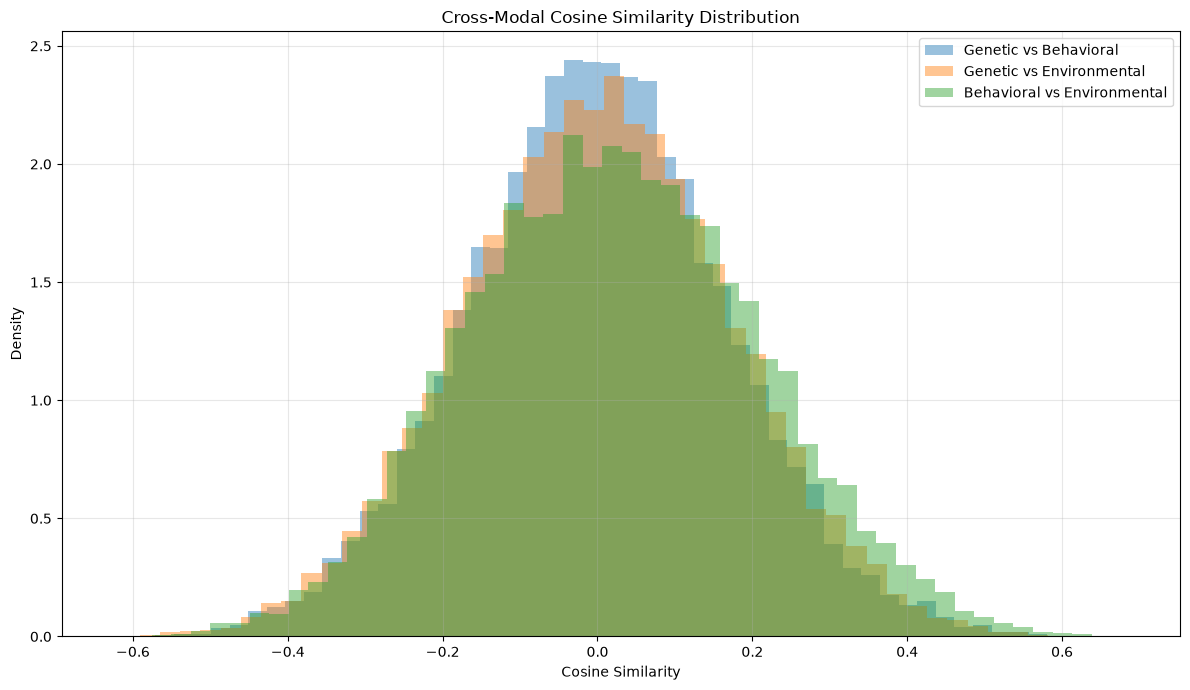

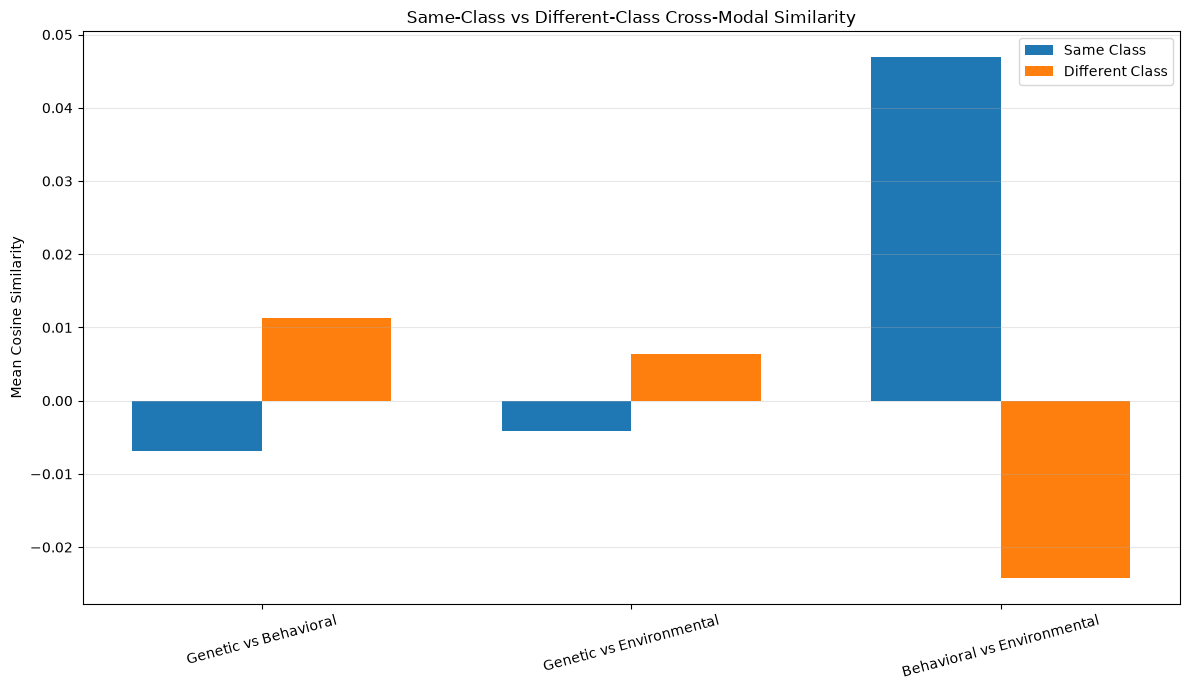


Generated Figures:
1. 01_07_overall_cross_modal_similarity_distribution.png
2. 01_07_same_vs_different_class_similarity.png

✓ VISUALIZATION COMPLETED


In [7]:
# =============================================================================
# CELL 7 — VISUALIZE CROSS-MODAL SIMILARITY
# =============================================================================

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Output directories
# ------------------------------------------------------------

FIGURE_DIR = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "01_embedding_analysis"
    / "figures"
)

REPORT_DIR = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "01_embedding_analysis"
    / "reports"
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 100)
print("CROSS-MODAL SIMILARITY VISUALIZATION")
print("=" * 100)


# ============================================================
# FIGURE 1 — Overall Similarity Distributions
# ============================================================

plt.figure(figsize=(12, 7))

for comparison, similarity_matrix in similarity_matrices.items():
    
    similarity_values = similarity_matrix.flatten()
    
    plt.hist(
        similarity_values,
        bins=50,
        alpha=0.45,
        density=True,
        label=comparison.replace("_vs_", " vs ")
    )

plt.xlabel("Cosine Similarity")
plt.ylabel("Density")
plt.title(
    "Cross-Modal Cosine Similarity Distribution"
)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

figure_1_path = (
    FIGURE_DIR
    / "01_07_overall_cross_modal_similarity_distribution.png"
)

plt.savefig(
    figure_1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FIGURE 2 — Same vs Different Class Similarity
# ============================================================

plot_data = same_vs_different_summary.copy()

x = np.arange(len(plot_data))
width = 0.35

plt.figure(figsize=(12, 7))

plt.bar(
    x - width / 2,
    plot_data["Same_Class_Mean_Similarity"],
    width,
    label="Same Class"
)

plt.bar(
    x + width / 2,
    plot_data["Different_Class_Mean_Similarity"],
    width,
    label="Different Class"
)

plt.xticks(
    x,
    plot_data["Comparison"],
    rotation=15
)

plt.ylabel("Mean Cosine Similarity")

plt.title(
    "Same-Class vs Different-Class Cross-Modal Similarity"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

figure_2_path = (
    FIGURE_DIR
    / "01_07_same_vs_different_class_similarity.png"
)

plt.savefig(
    figure_2_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print("\nGenerated Figures:")
print(f"1. {figure_1_path.name}")
print(f"2. {figure_2_path.name}")

print("\n" + "=" * 100)
print("✓ VISUALIZATION COMPLETED")
print("=" * 100)

In [8]:
# =============================================================================
# CELL 8 — SAVE REPORTS AND GENERATE ANALYSIS SUMMARY
# =============================================================================

from datetime import datetime

print("=" * 100)
print("STEP 01.7 — FINAL CROSS-MODAL SIMILARITY SUMMARY")
print("=" * 100)

# ------------------------------------------------------------
# Save reports
# ------------------------------------------------------------

overall_similarity_path = (
    REPORT_DIR
    / "01_07_overall_cross_modal_similarity.csv"
)

class_similarity_path = (
    REPORT_DIR
    / "01_07_class_conditional_similarity.csv"
)

same_different_path = (
    REPORT_DIR
    / "01_07_same_vs_different_class_similarity.csv"
)

sampling_summary_path = (
    REPORT_DIR
    / "01_07_balanced_sampling_summary.csv"
)

overall_similarity_summary.to_csv(
    overall_similarity_path,
    index=False
)

class_similarity_summary.to_csv(
    class_similarity_path,
    index=False
)

same_vs_different_summary.to_csv(
    same_different_path,
    index=False
)

sampling_summary.to_csv(
    sampling_summary_path,
    index=False
)


# ------------------------------------------------------------
# Print key findings
# ------------------------------------------------------------

print("\nKEY CROSS-MODAL RESULTS")
print("-" * 100)

for _, row in same_vs_different_summary.iterrows():
    
    print(f"\n{row['Comparison']}")
    print(
        f"  Same-class similarity      : "
        f"{row['Same_Class_Mean_Similarity']:.6f}"
    )
    print(
        f"  Different-class similarity : "
        f"{row['Different_Class_Mean_Similarity']:.6f}"
    )
    print(
        f"  Similarity gap             : "
        f"{row['Similarity_Gap']:.6f}"
    )
    print(
        f"  Interpretation             : "
        f"{row['Interpretation']}"
    )


# ------------------------------------------------------------
# Overall compatibility assessment
# ------------------------------------------------------------

positive_gaps = (
    same_vs_different_summary["Similarity_Gap"] > 0
).sum()

total_comparisons = len(
    same_vs_different_summary
)

if positive_gaps == total_comparisons:
    
    overall_conclusion = (
        "All modality pairs show higher same-class than different-class "
        "similarity. This provides preliminary evidence of class-level "
        "cross-modal representation compatibility."
    )

elif positive_gaps > 0:
    
    overall_conclusion = (
        "Some modality pairs show higher same-class similarity, while others "
        "do not. This suggests partial and modality-dependent class-level "
        "cross-modal compatibility."
    )

else:
    
    overall_conclusion = (
        "Same-class similarity does not consistently exceed different-class "
        "similarity. Strong class-level compatibility is not established "
        "by cosine similarity alone."
    )


# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------

final_summary = pd.DataFrame([
    {
        "Analysis": "Cross-Modal Cosine Similarity",
        "Analysis_Level": "Knowledge-Level",
        "Patient_Level_Matching": "Not Used",
        "Modalities_Analyzed": 3,
        "Balanced_Samples_Per_Modality": 116,
        "Class_Balance": "29 NON-ASD, 87 ASD",
        "Modality_Pairs_Analyzed": total_comparisons,
        "Pairs_With_Positive_Same_Class_Gap": positive_gaps,
        "Overall_Conclusion": overall_conclusion,
        "Timestamp": datetime.now().strftime(
            "%Y-%m-%d %H:%M:%S"
        )
    }
])

final_summary_path = (
    REPORT_DIR
    / "01_07_cross_modal_similarity_final_summary.csv"
)

final_summary.to_csv(
    final_summary_path,
    index=False
)


print("\n" + "=" * 100)
print("SCIENTIFIC CONCLUSION")
print("=" * 100)

print(overall_conclusion)

print("\nMethodological Note:")
print(
    "All comparisons were performed at the representation and class level."
)
print(
    "No patient identity correspondence was assumed between modalities."
)
print(
    "Cosine similarity evaluates directional compatibility between learned "
    "embedding representations, not individual patient matching."
)

print("\n" + "=" * 100)
print("✓ STEP 01.7 COMPLETED")
print("✓ KNOWLEDGE-LEVEL CROSS-MODAL ANALYSIS PRESERVED")
print("✓ NO PATIENT-LEVEL ASSUMPTIONS MADE")
print("=" * 100)

print("\nGenerated Reports:")
print(f"1. {overall_similarity_path.name}")
print(f"2. {class_similarity_path.name}")
print(f"3. {same_different_path.name}")
print(f"4. {sampling_summary_path.name}")
print(f"5. {final_summary_path.name}")

print("\nGenerated Figures:")
print("1. 01_07_overall_cross_modal_similarity_distribution.png")
print("2. 01_07_same_vs_different_class_similarity.png")

print("\nNext Logical Step:")
print(
    "01.8 — Class Centroid Analysis"
)

STEP 01.7 — FINAL CROSS-MODAL SIMILARITY SUMMARY

KEY CROSS-MODAL RESULTS
----------------------------------------------------------------------------------------------------

Genetic vs Behavioral
  Same-class similarity      : -0.006907
  Different-class similarity : 0.011342
  Similarity gap             : -0.018249
  Interpretation             : Different-class representations show higher cross-modal similarity

Genetic vs Environmental
  Same-class similarity      : -0.004102
  Different-class similarity : 0.006408
  Similarity gap             : -0.010510
  Interpretation             : Different-class representations show higher cross-modal similarity

Behavioral vs Environmental
  Same-class similarity      : 0.046893
  Different-class similarity : -0.024174
  Similarity gap             : 0.071067
  Interpretation             : Same-class representations show higher cross-modal similarity

SCIENTIFIC CONCLUSION
Some modality pairs show higher same-class similarity, while others do